# Echo Problem Bank Analysis

**Goal:** Measure the bank's size, topic–level coverage, duplicate review candidates, and the checker's detection of constructed wrong answers.

This is a reproducible, read-only analysis. It does not change the source bank, math checker, or approved project plan, and makes no AI calls. **Existing Level 1–4 ratings are retained; this analysis does not assign or independently validate difficulty levels.**

**Source:** `docs/verified_problems.json`, imported from GitHub baseline commit `bc58c8aef0daf55e566176436895ee707197e7bf`. The output records the SHA-256 of the actual analyzed file.

“Eligible” follows the existing audit rules. **It does not mean every answer has been independently proven correct by this analysis.**

## 1. Locate the project and run the analysis

`Path` locates the files; `subprocess.run` executes the project's analysis script. We use the project's `.venv` Python when available, otherwise the current notebook's Python. Install the dependencies described in `analysis/README.md` before running.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "docs/verified_problems.json").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook from the Echo project folder.")
sys.path.insert(0, str(root))
venv_python = root / ".venv" / ("Scripts/python.exe" if sys.platform == "win32" else "bin/python")
python = str(venv_python) if venv_python.exists() else sys.executable
result = subprocess.run([python, "scripts/analyze_bank.py"], cwd=root,
                        capture_output=True, text=True, check=True)
print(result.stdout)
report = json.loads((root / "build/bank_analysis/report.json").read_text(encoding="utf-8"))
summary = report["summary"]
print("Bank SHA-256:", report["source"]["sha256"])


Bank: 3510 rows / 90 topics
Levels 1–4: 3450; eligible 3405; excluded 45; level 5 out of scope 60
Topics with eligible rows: 88; with >=3 at all four levels: 78
Topic × level cells: 19 empty, 0 with 1–2 rows
Exact repeated-statement groups: 11 (review, not automatic deletion)
Power-rule baseline keys accepted: 40/40; deliberately wrong cases caught: 120/120
Results: ./build/bank_analysis

Bank SHA-256: b254e1cb2e55be28740a37f88cb167de72391ff52fb06861107f4f04e72f2007


## 2. Reconcile totals, scope, and exclusions

Each bank record represents one problem. The MVP uses levels 1–4; level 5 is reported separately. We reuse `scripts/audit_bank.py` to identify missing figure references and undefined functions, then reconcile the totals. These are heuristic eligibility checks, not exhaustive mathematical validation.

In [2]:
from scripts.audit_bank import load_bank, build_report
bank = load_bank(root / "docs/verified_problems.json")
audit = build_report(bank)
assert summary["eligible"] == audit["eligible_count"]
assert summary["in_scope_1_4"] == summary["eligible"] + summary["excluded"]
assert summary["total"] == summary["in_scope_1_4"] + summary["level_5_out_of_scope"]
print(f"Total bank problems: {summary['total']:,}; topics: {summary['topics']}")
print(f"In scope, levels 1–4: {summary['in_scope_1_4']:,}; audit-eligible: {summary['eligible']:,}; excluded: {summary['excluded']}")
print("Exclusion reasons: ", report["excluded_by_reason"])
print("Reconciliation passed: counts match the existing audit.")


Total bank problems: 3,510; topics: 90
In scope, levels 1–4: 3,450; audit-eligible: 3,405; excluded: 45
Exclusion reasons:  {'figure_reference': 40, 'undefined_function': 5}
Reconciliation passed: counts match the existing audit.


## 3. Difficulty distribution

The chart shows **eligible problem counts**, not student ability or independently validated difficulty ratings. Values come directly from the analysis output. The chart uses SVG and does not require a plotting package.

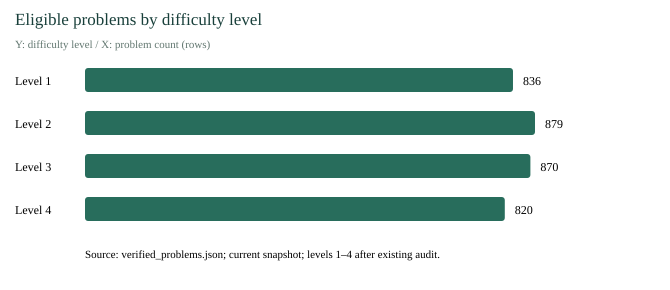

1252

In [3]:
from html import escape
from IPython.display import SVG, display

def level_chart(counts):
    width, height = 670, 290
    max_count = max(counts.values())
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" role="img" aria-label="Eligible problem count by difficulty level">',
             '<rect width="100%" height="100%" fill="white"/>',
             '<text x="15" y="25" font-size="17" fill="#183f3a">Eligible problems by difficulty level</text>',
             '<text x="15" y="48" font-size="11" fill="#627770">Y: difficulty level / X: problem count (rows)</text>']
    for i, (level, count) in enumerate(counts.items()):
        y = 68 + i * 43
        bar_width = count / max_count * 450
        parts += [f'<text x="15" y="{y+17}" font-size="12">Level {escape(str(level))}</text>',
                  f'<rect x="85" y="{y}" width="{bar_width}" height="24" rx="3" fill="#286d5c"/>',
                  f'<text x="{95+bar_width}" y="{y+17}" font-size="12">{count}</text>']
    parts += ['<text x="85" y="258" font-size="11">Source: verified_problems.json; current snapshot; levels 1–4 after existing audit.</text>', '</svg>']
    return "".join(parts)
chart = level_chart(report["eligible_by_level"])
display(SVG(chart))
(root / "build/bank_analysis/eligible_by_level.svg").write_text(chart, encoding="utf-8")


## 4. Can every topic supply three problems at every level?

We inspect the quantity in each of `90 topics × 4 levels`. A large bank does not ensure that every cell has problems. Three eligible rows is a product quantity threshold, not a guarantee of mathematically distinct tasks, accurate ratings, or a match to a student's confirmed task and answer type.

In [4]:
print(f"Topics with at least three eligible rows at every level: {summary['topics_with_three_at_every_level']}/{summary['topics']}")
print(f"Empty topic–level cells: {summary['empty_topic_level_cells']}; cells with only 1–2 rows: {summary['thin_topic_level_cells']}")
print("\nComplete coverage gap list:")
for row in report["coverage_gaps"]:
    print(f"  {row['topic']} | L{row['level']} | {row['eligible_count']} eligible rows")
print("\nUI recommendation: disclose insufficient pools; never silently label a different level as the requested one.")


Topics with at least three eligible rows at every level: 78/90
Empty topic–level cells: 19; cells with only 1–2 rows: 0

Complete coverage gap list:
  average_value | L1 | 0 eligible rows
  basic_antiderivatives | L4 | 0 eligible rows
  curve_sketching | L1 | 0 eligible rows
  definite_properties | L3 | 0 eligible rows
  definite_properties | L4 | 0 eligible rows
  ftc_evaluate | L4 | 0 eligible rows
  increasing_decreasing/variants/graph | L1 | 0 eligible rows
  increasing_decreasing/variants/graph | L2 | 0 eligible rows
  increasing_decreasing/variants/graph | L3 | 0 eligible rows
  increasing_decreasing/variants/graph | L4 | 0 eligible rows
  initial_value_problems | L1 | 0 eligible rows
  linear_approximation | L4 | 0 eligible rows
  relative_extrema | L1 | 0 eligible rows
  relative_extrema/variants/graph | L1 | 0 eligible rows
  relative_extrema/variants/graph | L2 | 0 eligible rows
  relative_extrema/variants/graph | L3 | 0 eligible rows
  relative_extrema/variants/graph | L4 | 

## 5. Repeated statements, reused IDs, and shared templates

- **Repeated statement text:** compared after collapsing whitespace. Cross-topic reuse can be intentional and needs review.
- **Reused IDs:** two topics may each contain an `AE01`. The record key should be `(topic, id)`.
- **Number-masked templates:** structurally similar practice variants may be intentional. These are manual-review candidates, not confirmed duplicates, and are not automatically removed. Text matching also misses some mathematically equivalent problems.

In [5]:
print(f"Repeated statement text: {summary['exact_statement_groups']} groups / {summary['exact_statement_rows']} rows")
print(f"Within-topic groups: {summary['same_topic_repeated_statement_groups']}; cross-topic groups: {summary['cross_topic_repeated_statement_groups']} groups")
print(f"Reused ID values: {summary['reused_id_groups']} groups; involving {summary['rows_with_reused_id']} rows; duplicate (topic, ID) keys: {summary['duplicate_topic_id_keys']}")
print(f"Number-masked template candidates: {summary['number_masked_template_groups']} groups (not confirmed duplicates)")
for group in report["exact_statement_groups"]:
    if len(group["topics"]) == 1 or group["different_written_answers"]:
        print("\nPriority review: ", group["references"])
        print("Statement: ", group["statement"])
        print("Written answer forms: ", group["written_answers"])
print("\nDifferent written forms do not necessarily conflict. No problems were automatically edited or deleted.")


Repeated statement text: 11 groups / 22 rows
Within-topic groups: 1; cross-topic groups: 10 groups
Reused ID values: 250 groups; involving 500 rows; duplicate (topic, ID) keys: 0
Number-masked template candidates: 621 groups (not confirmed duplicates)

Priority review:  ['hyperbolic::HY33', 'trig_substitution::TS05']
Statement:  Find $\displaystyle \int \frac{1}{\sqrt{x^{2} + 1}}\,dx$.
Written answer forms:  ['\\ln{\\left(\\left|{x + \\sqrt{x^{2} + 1}}\\right| \\right)} + C', '\\ln{\\left(x + \\sqrt{x^{2} + 1} \\right)} + C']

Priority review:  ['strategy::ST12', 'strategy::ST16']
Statement:  Find $\displaystyle \int \tan^{2}{\left(x \right)} \sec^{2}{\left(x \right)}\,dx$.
Written answer forms:  ['\\frac{\\tan^{3}{\\left(x \\right)}}{3} + C']

Different written forms do not necessarily conflict. No problems were automatically edited or deleted.


## 6. Does a missing field always mean bad data?

Enum answers such as “diverges” or “does not exist” can legitimately lack a SymPy expression. Inspect the answer type before treating missing metadata as a failure. This analysis does not exclude problems merely because a symbolic string is absent.

In [6]:
from collections import Counter
print("Answer types across the full bank: ", report["all_answer_types"])
print("Metadata findings: ", dict(Counter(reason for row in report["metadata_findings"] for reason in row["reasons"])))
print("Answer types of flagged records: ", sorted({row["answer_type"] for row in report["metadata_findings"]}))
print("These informational findings do not change the existing audit eligibility count.")


Answer types across the full bank:  {'enum': 280, 'expression': 706, 'interval': 150, 'multi_part': 96, 'numeric': 2113, 'set': 165}
Metadata findings:  {'missing_sympy_string': 190}
Answer types of flagged records:  ['enum']
These informational findings do not change the existing audit eligibility count.


## 7. Construct wrong answers and test the checker

Negative tests cover the supported `power_rule` subset only. We reuse `core/corrupt.py` and `core/derivative_checker.py`: first verify that the bank key is accepted, then add one, double, or negate it and run the actual checker. A bank key that cannot be accepted is not treated as a successfully constructed negative case.

This measures consistency with the bank and detection of **three specific error mutations**. It is not an all-calculus accuracy estimate or an estimate of detection on real AI-generated errors.

In [7]:
negative = report["negative_tests"]
print(f"Original bank keys accepted: {negative['positive_accepted']}/{negative['positive_count']}")
print(f"Constructed wrong keys detected: {negative['detected']}/{negative['case_count']}")
example = next(case for case in negative["cases"] if case["detected"])
for key in ["topic", "id", "statement", "correct_key", "mutation", "wrong_key", "observed", "reason"]:
    print(f"{key}: {example[key]}")
print("\nThese are constructed tests, not recorded AI mistakes. The bank may come from similar checking code; this is not independent proof.")


Original bank keys accepted: 40/40
Constructed wrong keys detected: 120/120
topic: power_rule
id: PR01
statement: Find $f'(x)$ for $f(x) = x^{4} + 3 x^{2} + 7$.
correct_key: 4 x^{3} + 6 x
mutation: add_one
wrong_key: 4 x^{3} + 6 x + 1
observed: wrong_key
reason: at x = 0.3137 the checker computes 2.00568 but the key gives 3.00568

These are constructed tests, not recorded AI mistakes. The bank may come from similar checking code; this is not independent proof.


## 8. Export and hand off

Full JSON results, CSV detail files, and the offline HTML report are written to `build/bank_analysis/`. This is an analysis contribution to the existing Echo project, not a separate Math Tutor application. No bank records or checker rules were changed.

In [8]:
rendered = subprocess.run([python, "analysis/render_report.py", "--lang", "en"], cwd=root,
                          capture_output=True, text=True, check=True)
print("English browser report: ", rendered.stdout.strip())
print("\nExported files:")
for path in sorted((root / "build/bank_analysis").iterdir()):
    print(" ", path.name)
print("\nHandoff: review insufficient pools with Josh and confirm whether strategy::ST12 / strategy::ST16 should be deduplicated.")


English browser report:  ./build/bank_analysis/Echo_Bank_Analysis_Report.html

Exported files:
  coverage_gaps.csv
  eligible_by_level.svg
  exact_statement_groups.csv
  excluded_problems.csv
  id_collisions.csv
  metadata_findings.csv
  negative_test_cases.csv
  Echo_Bank_Analysis_Report.html
  report.html
  report.json
  template_review_candidates.csv
  topic_coverage.csv

Handoff: review insufficient pools with Josh and confirm whether strategy::ST12 / strategy::ST16 should be deduplicated.
